# Lecture 4 — Class Exercise
## Scatter & Bubble Charts: Gapminder

> **Push to:** `week04/lecture04_exercise.ipynb`

**Rules:**
1. Colour used **sparingly** — one categorical variable, no rainbow
2. If showing all continents, either use accessible palette OR grey all + highlight one
3. `size_max` set when using bubble size
4. Log scale for GDP per capita
5. Insight title

---


In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.io as pio

# Make charts visible on any viewer (GitHub, nbviewer, Colab, etc.):
# render as a static PNG so the chart is stored inside the saved notebook.
# Needs:  pip install -U kaleido   (falls back to interactive if missing)
try:
    import kaleido
    pio.renderers.default = 'png'
except ImportError:
    pio.renderers.default = 'notebook_connected'


# Dataset: Gapminder — GDP, Life Expectancy, Population by Country
# Source: Gapminder Foundation (gapminder.org)

df = px.data.gapminder()
print(f"Loaded: {len(df)} rows")
print(df.head())

Loaded: 1704 rows
       country continent  year  lifeExp       pop   gdpPercap iso_alpha  \
0  Afghanistan      Asia  1952   28.801   8425333  779.445314       AFG   
1  Afghanistan      Asia  1957   30.332   9240934  820.853030       AFG   
2  Afghanistan      Asia  1962   31.997  10267083  853.100710       AFG   
3  Afghanistan      Asia  1967   34.020  11537966  836.197138       AFG   
4  Afghanistan      Asia  1972   36.088  13079460  739.981106       AFG   

   iso_num  
0        4  
1        4  
2        4  
3        4  
4        4  


In [2]:
# explore

print(df.info())
print("Years:", sorted(df['year'].unique()))
print("Continents:", df['continent'].unique())
print(df.describe().round(1))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    1704 non-null   object 
 1   continent  1704 non-null   object 
 2   year       1704 non-null   int64  
 3   lifeExp    1704 non-null   float64
 4   pop        1704 non-null   int64  
 5   gdpPercap  1704 non-null   float64
 6   iso_alpha  1704 non-null   object 
 7   iso_num    1704 non-null   int64  
dtypes: float64(2), int64(3), object(3)
memory usage: 106.6+ KB
None
Years: [np.int64(1952), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)]
Continents: ['Asia' 'Europe' 'Africa' 'Americas' 'Oceania']
         year  lifeExp           pop  gdpPercap  iso_num
count  1704.0   1704.0  1.704000e+03     1704.0   1704.0
mean   1979.5     59.5  2.960121e+07     7215.3    

## Task 1 — Scatter: life expectancy change over time

**What to build:** A scatter showing **GDP per capita vs life expectancy** for **two years** (2002 and 2007) to show how both moved — use **colour for year** (just 2 colours), **one continent only**.

Choose any continent except Africa (that was the example). Highlight the change direction.

> 💡 Filter: `df.loc[df['continent'] == 'YOUR_CHOICE']` then filter years


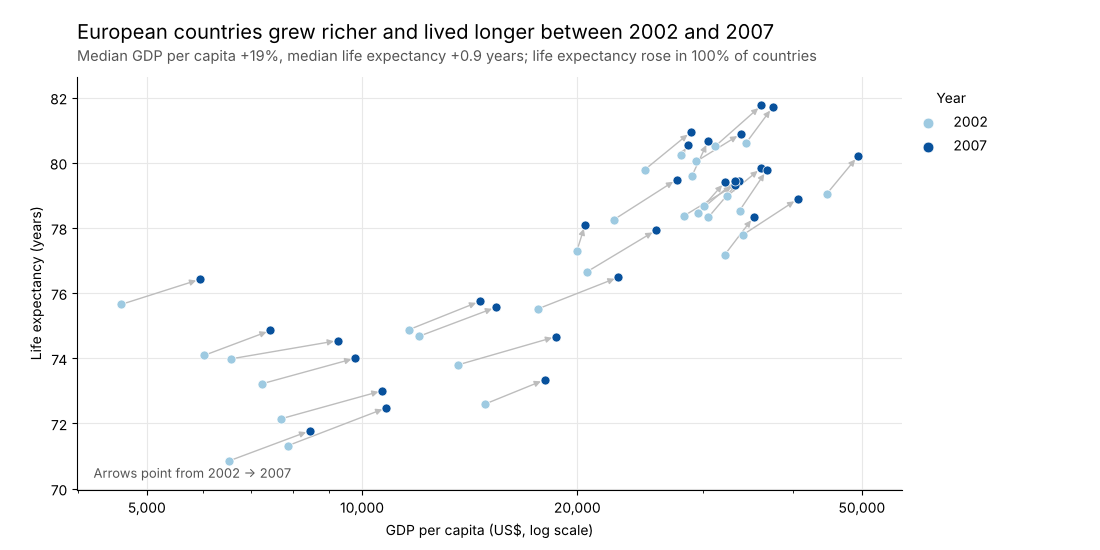

In [3]:
# Task 1 — Europe, 2002 vs 2007
continent = 'Europe'

sub = df.loc[(df['continent'] == continent) & (df['year'].isin([2002, 2007]))].copy()
sub['year'] = sub['year'].astype(str)

# Summary numbers for the insight title
wide = sub.pivot(index='country', columns='year', values=['gdpPercap', 'lifeExp'])
gdp_growth = (wide[('gdpPercap', '2007')] / wide[('gdpPercap', '2002')] - 1).median() * 100
life_gain = (wide[('lifeExp', '2007')] - wide[('lifeExp', '2002')]).median()
share_up = ((wide[('lifeExp', '2007')] - wide[('lifeExp', '2002')]) > 0).mean() * 100

fig = px.scatter(
    sub,
    x='gdpPercap',
    y='lifeExp',
    color='year',                                   # only 2 colours: one variable
    color_discrete_map={'2002': '#9ecae1', '2007': '#08519c'},
    category_orders={'year': ['2002', '2007']},
    hover_name='country',
    log_x=True,                                     # log scale for GDP per capita
    labels={'gdpPercap': 'GDP per capita (US$, log scale)',
            'lifeExp': 'Life expectancy (years)',
            'year': 'Year'},
    title=(f'European countries grew richer and lived longer between 2002 and 2007<br>'
           f'<sup>Median GDP per capita +{gdp_growth:.0f}%, median life expectancy +{life_gain:.1f} years; '
           f'life expectancy rose in {share_up:.0f}% of countries</sup>'),
)

# Arrows from each country's 2002 position to its 2007 position (change direction)
# NB: on a log axis, annotation coordinates are in log10 units
for country, r in wide.iterrows():
    fig.add_annotation(
        x=np.log10(r[('gdpPercap', '2007')]), y=r[('lifeExp', '2007')],
        ax=np.log10(r[('gdpPercap', '2002')]), ay=r[('lifeExp', '2002')],
        xref='x', yref='y', axref='x', ayref='y',
        text='', showarrow=True,
        arrowhead=2, arrowsize=1, arrowwidth=1, arrowcolor='#bdbdbd',
    )

fig.add_annotation(
    text='Arrows point from 2002 → 2007',
    xref='paper', yref='paper', x=0.02, y=0.04,
    showarrow=False, font=dict(size=12, color='#555'),
)

fig.update_traces(marker=dict(size=9, line=dict(width=0.5, color='white')))
fig.update_layout(template='plotly_white', legend_title_text='Year', height=550)
fig.show()


## Task 2 — Bubble chart: tell a story

**What to build:** A bubble chart (full 2007 dataset, all countries) where:
- x = GDP per capita (log scale)
- y = life expectancy
- size = population
- colour = ONE continent highlighted (your choice), all others grey
- At least one annotation explaining the highlighted group's story

> This is the grey-and-highlight technique applied to a bubble chart.


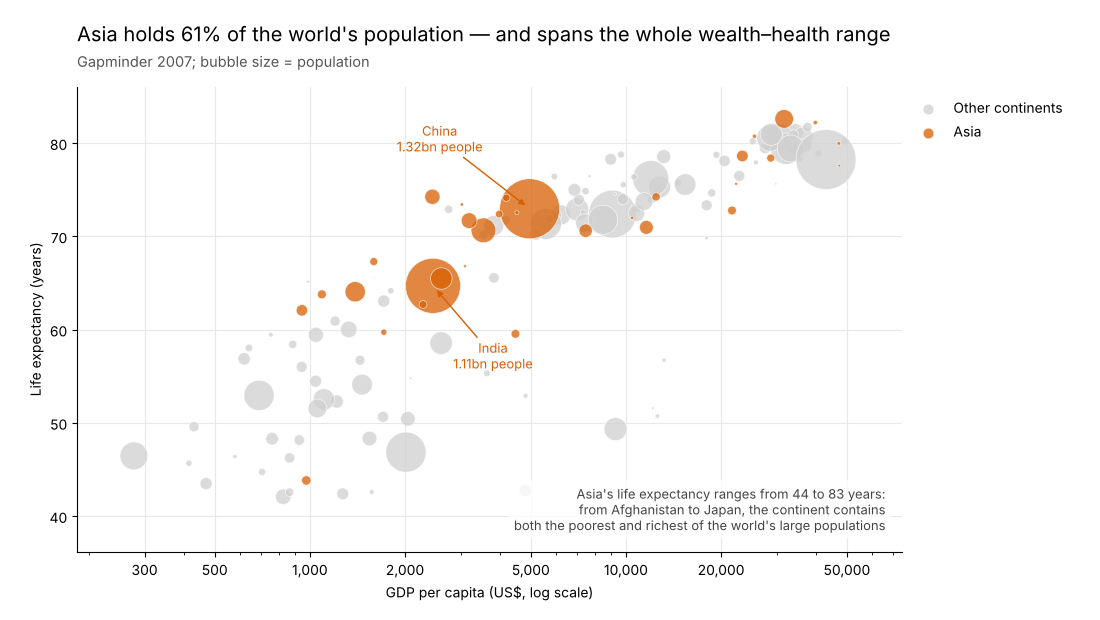

In [4]:
# Task 2 — Highlight Asia in 2007, everything else grey
highlight = 'Asia'

d07 = df.loc[df['year'] == 2007].copy()
d07['group'] = np.where(d07['continent'] == highlight, highlight, 'Other continents')

asia = d07[d07['continent'] == highlight]
asia_min, asia_max = asia['lifeExp'].min(), asia['lifeExp'].max()
asia_pop_share = asia['pop'].sum() / d07['pop'].sum() * 100

fig = px.scatter(
    d07,
    x='gdpPercap',
    y='lifeExp',
    size='pop',
    size_max=60,                                    # cap bubble size
    color='group',
    color_discrete_map={highlight: '#d95f02', 'Other continents': '#d0d0d0'},
    category_orders={'group': ['Other continents', highlight]},   # grey drawn first, highlight on top
    hover_name='country',
    hover_data={'pop': ':,', 'group': False},
    log_x=True,
    labels={'gdpPercap': 'GDP per capita (US$, log scale)',
            'lifeExp': 'Life expectancy (years)',
            'pop': 'Population',
            'group': ''},
    title=(f'Asia holds {asia_pop_share:.0f}% of the world\'s population — and spans the whole wealth–health range<br>'
           f'<sup>Gapminder 2007; bubble size = population</sup>'),
)

# Grey bubbles: semi-transparent, thin outline
fig.update_traces(marker=dict(opacity=0.75, line=dict(width=0.5, color='white')))

# Annotation 1: the two giants
for name, ax_, ay_ in [('China', -90, -70), ('India', 60, 70)]:
    r = d07.loc[d07['country'] == name].iloc[0]
    fig.add_annotation(
        x=np.log10(r['gdpPercap']), y=r['lifeExp'],
        text=f"<b>{name}</b><br>{r['pop']/1e9:.2f}bn people",
        showarrow=True, arrowhead=2, ax=ax_, ay=ay_,
        font=dict(size=12, color='#d95f02'), arrowcolor='#d95f02',
    )

# Annotation 2: the story of the group
fig.add_annotation(
    text=(f'Asia\'s life expectancy ranges from {asia_min:.0f} to {asia_max:.0f} years:<br>'
          'from Afghanistan to Japan, the continent contains<br>'
          'both the poorest and richest of the world\'s large populations'),
    xref='paper', yref='paper', x=0.98, y=0.04, xanchor='right', yanchor='bottom',
    showarrow=False, align='right', font=dict(size=12, color='#444'),
    bgcolor='rgba(255,255,255,0.8)',
)

fig.update_layout(template='plotly_white', legend_title_text='', height=620)
fig.show()
